# Fourier Analysis Demo
Showcase of base experiments to analyse Fourier space of solution

## 0 - Setup

In [42]:
%load_ext autoreload
%autoreload 2

import torch
import numpy as np
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

import sys
import os

# Adds the parent directory (root of your project) to the python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.models  import MerlinHeatQPINN, ClassicalHeatQPINN, MerlinTunableSimple
from src.pde     import HeatEquation, WaveEquation
from src.loss    import total_loss
from src.train   import train
from src.eval    import evaluate
from src.plotter import (
    plot_training_history,
    plot_solution_comparison,
    plot_power_spectrum,
    plot_mode_l2_errors,
    plot_frequency_sweep,
    plot_multi_model_l2_error
)
from src.utils import hilbert_space_dimension, quantum_outputsize_for_param_match, find_matching_hidden_readout

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device: cpu  |  dtype: torch.float32


## 1 - Frequency Sweep
Train both models on heat equatin over a range of IC frequencies

In [47]:
#FREQUENCIES = [0.5, 1.0, 1.5, 2, 2.5, 3, 3.5, 4.0, 4.5]
FREQUENCIES = [3, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0]
#SEEDS = [42]#, 666, 69, 67, 13]
SEEDS = [120]

In [48]:
FEATURE_SIZES_guess = [3]#[2,4,8,16]
FEATURE_SIZE, HIDDEN_READOUT = find_matching_hidden_readout(feature_sizes=FEATURE_SIZES_guess, ranges=[1,100])

print(FEATURE_SIZE)
print(HIDDEN_READOUT)
#select smallest
FEATURE_SIZE = FEATURE_SIZE[0]
HIDDEN_READOUT = HIDDEN_READOUT[0]
QUANTUM_OUTPUT_SIZE = int(quantum_outputsize_for_param_match(FEATURE_SIZE, HIDDEN_READOUT))

[[  1   1]
 [  1   2]
 [  1   3]
 ...
 [ 98 100]
 [ 99 100]
 [100 100]]
[3]
[4]


In [49]:
sweep_results = {"classical": [], "qpinn_weights": []} #"qpinn": [], 
for freq in FREQUENCIES:
    #pde = HeatEquation(freq=freq)
    pde = WaveEquation(freq=freq,c=0.5)
    print(f"\n{'='*60}\nfreq = {freq}")
    seed_results = {"classical": [], "qpinn_weights": []}
    for i,seed in enumerate(SEEDS):
        # --- QPINN ---
#        qpinn = MerlinHeatQPINN(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, pde=pde).to(device)
#        train(model=qpinn, pde=pde, loss_fn=total_loss, log_every=100, seed=seed)
#        metrics, _, _, _, _ = evaluate(model=qpinn, pde=pde, device=device, dtype=dtype)
#        sweep_results["qpinn"].append({"frequency": freq, "rel_l2": metrics["rel_l2"]})
#        print(f"  QPINN_SEED_{seed}      rel_l2 = {metrics['rel_l2']:.4e}")

        # --- Classical ---
        classical = ClassicalHeatQPINN(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, quantum_output_size=QUANTUM_OUTPUT_SIZE, pde = pde).to(device)
        train(model=classical, pde=pde, loss_fn=total_loss, log_every=100, seed=seed, epochs=600)
        metrics, _, _, _, _ = evaluate(model=classical, pde=pde, device=device, dtype=dtype)
        seed_results["classical"].append(metrics["rel_l2"])
        
        print(f"  Classical_SEED_{seed}   rel_l2 = {metrics['rel_l2']:.4e}")

        # --- QPINN WEIGHTS ---
        qpinn_weights = MerlinTunableSimple(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, pde=pde).to(device)
        train(model=qpinn_weights, pde=pde, loss_fn=total_loss, log_every=100, seed=seed, epochs=600)
        metrics, _, _, _, _ = evaluate(model=qpinn_weights, pde=pde, device=device, dtype=dtype)
        seed_results["qpinn_weights"].append(metrics["rel_l2"])
        print(f"  QPINN WEIGHTS_SEED_{seed}   rel_l2 = {metrics['rel_l2']:.4e}")
    
    sweep_results["classical"].append({"frequency": freq, "rel_l2": seed_results["classical"]})
    sweep_results["qpinn_weights"].append({"frequency": freq, "rel_l2": seed_results["qpinn_weights"]})



freq = 3
Parameters — total: 177  trainable: 177

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 2.5085e+02 | PDE: 2.46e+02 | Cons: 4.44e+01 | IC: 0.00e+00 | BC: 5.69e-16 | Time: 0.0s
Epoch   100/600 | Loss: 2.5510e+02 | PDE: 2.51e+02 | Cons: 4.45e+01 | IC: 0.00e+00 | BC: 5.69e-16 | Time: 0.3s
Epoch   200/600 | Loss: 2.5770e+02 | PDE: 2.54e+02 | Cons: 3.97e+01 | IC: 0.00e+00 | BC: 5.69e-16 | Time: 0.6s
Epoch   300/600 | Loss: 2.3835e+02 | PDE: 2.34e+02 | Cons: 4.77e+01 | IC: 0.00e+00 | BC: 5.69e-16 | Time: 0.8s
Epoch   400/600 | Loss: 2.5594e+02 | PDE: 2.52e+02 | Cons: 4.12e+01 | IC: 0.00e+00 | BC: 5.69e-16 | Time: 1.1s
Epoch   500/600 | Loss: 2.6214e+02 | PDE: 2.58e+02 | Cons: 3.98e+01 | IC: 0.00e+00 | BC: 5.69e-16 | Time: 1.4s
Epoch   600/600 | Loss: 2.5353e+02 | PDE: 2.49e+02 | Cons: 4.53e+01 | IC: 0.00e+00 | BC: 5.69e-16 | Time: 1.7s

Done — 1.7s total
Evaluating on 60×60 grid …
  Relative L2 : 2.1197e+00
  MAE         : 7.7894e-01
  Max abs err : 2.

Saved: ../figures/fourier_demo/freq_sweep.png


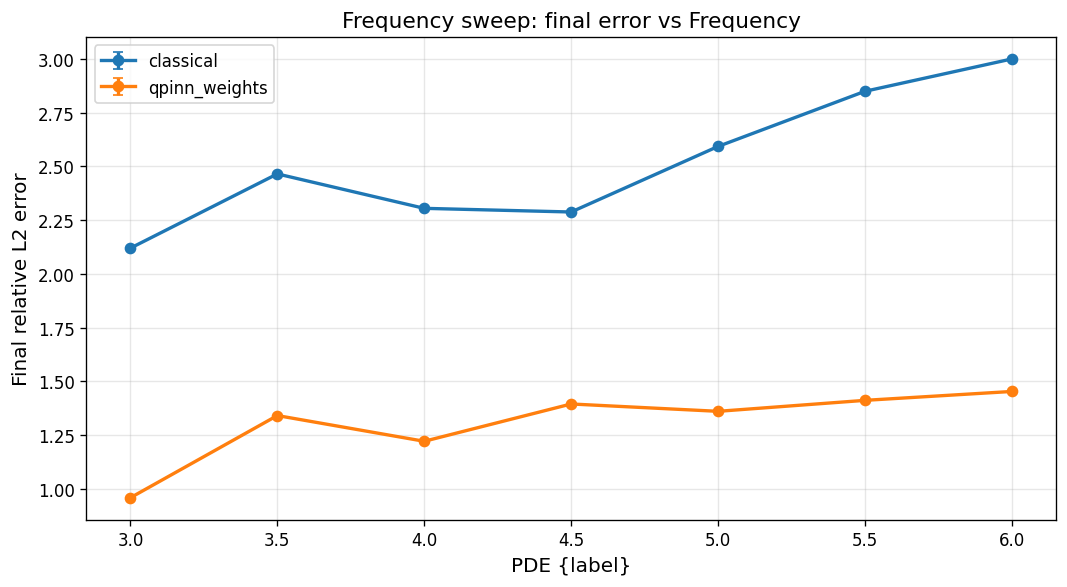

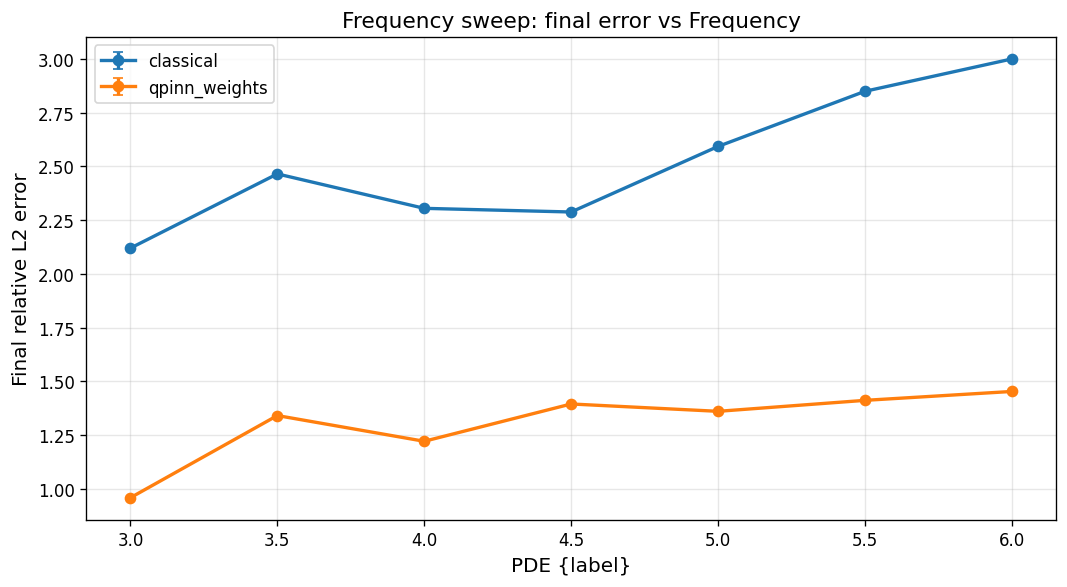

In [50]:
%reload_ext autoreload
plot_frequency_sweep(
    sweep_results,
    save_path = "../figures/fourier_demo/freq_sweep.png",
    show      = True,
)

## 2 - Train both models with same frequency and compare

In [66]:
FREQUENCY = 1

In [70]:

#ref_pde = HeatEquation(freq=FREQUENCY)
ref_pde = WaveEquation(freq=FREQUENCY, c=2.0)

# QPINN
qpinn_ref = MerlinHeatQPINN().to(device)
history_q = train(model=qpinn_ref, pde=ref_pde, epochs = 600)

# Classical
classical_ref = ClassicalHeatQPINN(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, quantum_output_size=QUANTUM_OUTPUT_SIZE, pde = ref_pde).to(device)
history_c = train(model=classical_ref, pde=ref_pde, epochs = 300)

qpinn_weights_ref = MerlinTunableSimple(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, pde=ref_pde).to(device)
history_qpinn_weights = train(model=qpinn_weights_ref, pde=ref_pde, epochs = 300)

Parameters — total: 250  trainable: 250

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 4.7381e+00 | PDE: 3.22e-05 | Cons: 2.05e-02 | IC: 4.74e-01 | BC: 2.52e-04 | Time: 0.0s
Epoch    50/600 | Loss: 1.6964e+00 | PDE: 3.93e-03 | Cons: 6.53e-04 | IC: 1.23e-01 | BC: 4.66e-01 | Time: 2.6s
Epoch   100/600 | Loss: 1.3653e+00 | PDE: 6.84e-03 | Cons: 5.49e-02 | IC: 1.07e-01 | BC: 2.85e-01 | Time: 5.3s
Epoch   150/600 | Loss: 1.2308e+00 | PDE: 1.16e-02 | Cons: 1.03e-01 | IC: 9.30e-02 | BC: 2.79e-01 | Time: 7.8s
Epoch   200/600 | Loss: 1.3142e+00 | PDE: 1.23e-02 | Cons: 1.26e-01 | IC: 1.05e-01 | BC: 2.35e-01 | Time: 10.4s
Epoch   250/600 | Loss: 1.3184e+00 | PDE: 1.05e-02 | Cons: 1.31e-01 | IC: 1.00e-01 | BC: 2.91e-01 | Time: 13.0s
Epoch   300/600 | Loss: 1.1127e+00 | PDE: 1.90e-02 | Cons: 9.44e-02 | IC: 8.31e-02 | BC: 2.53e-01 | Time: 15.5s
Epoch   350/600 | Loss: 1.0905e+00 | PDE: 2.24e-02 | Cons: 5.06e-02 | IC: 9.04e-02 | BC: 1.59e-01 | Time: 18.1s
Epoch   400/6

In [75]:
# Evaluate models
grid_n = 128


_, U_pred_q, U_true, x_grid, t_grid = evaluate(model=qpinn_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

_, U_pred_c, _,      _,      _      = evaluate(model=classical_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

_, U_pred_q_w, _,      _,      _      = evaluate(model=qpinn_weights_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

Evaluating on 128×128 grid …
  Relative L2 : 8.0860e-01
  MAE         : 3.3218e-01
  Max abs err : 9.5501e-01
  RMSE        : 4.0429e-01
Evaluating on 128×128 grid …
  Relative L2 : 1.4411e+00
  MAE         : 5.5209e-01
  Max abs err : 1.6451e+00
  RMSE        : 7.2055e-01
Evaluating on 128×128 grid …
  Relative L2 : 1.3050e+00
  MAE         : 5.0515e-01
  Max abs err : 1.3950e+00
  RMSE        : 6.5248e-01


#TODO : figure out here Q error is smaller than C error ??? this doesnt match results from other pipeline

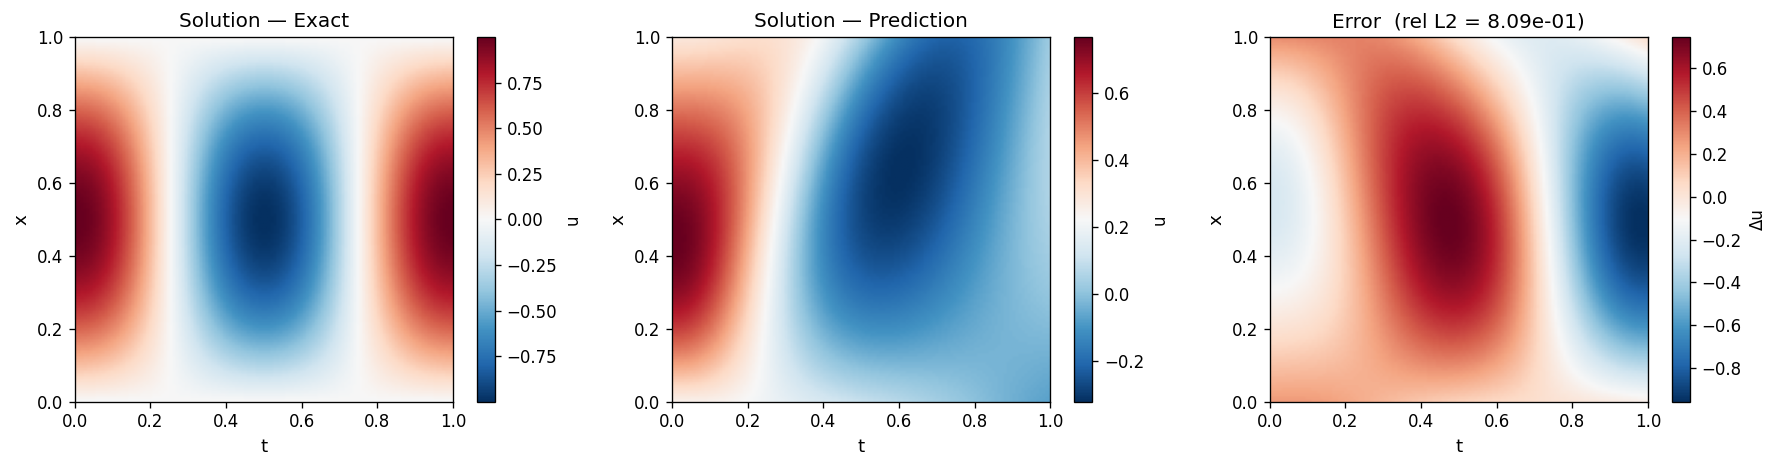

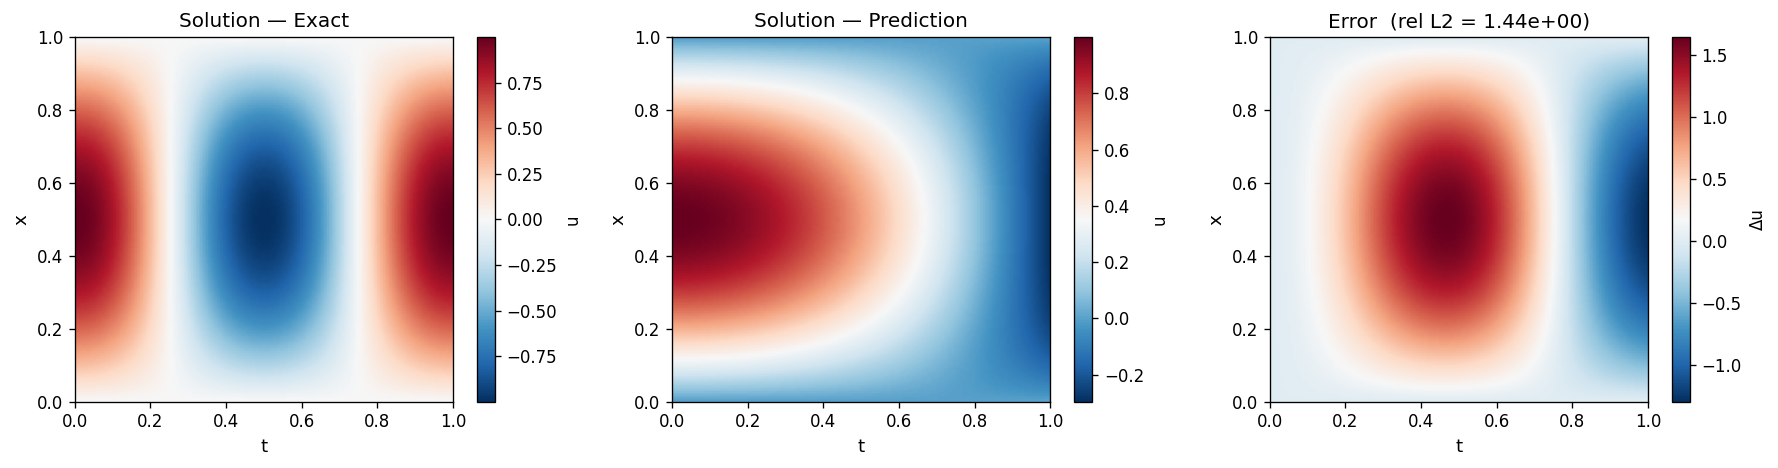

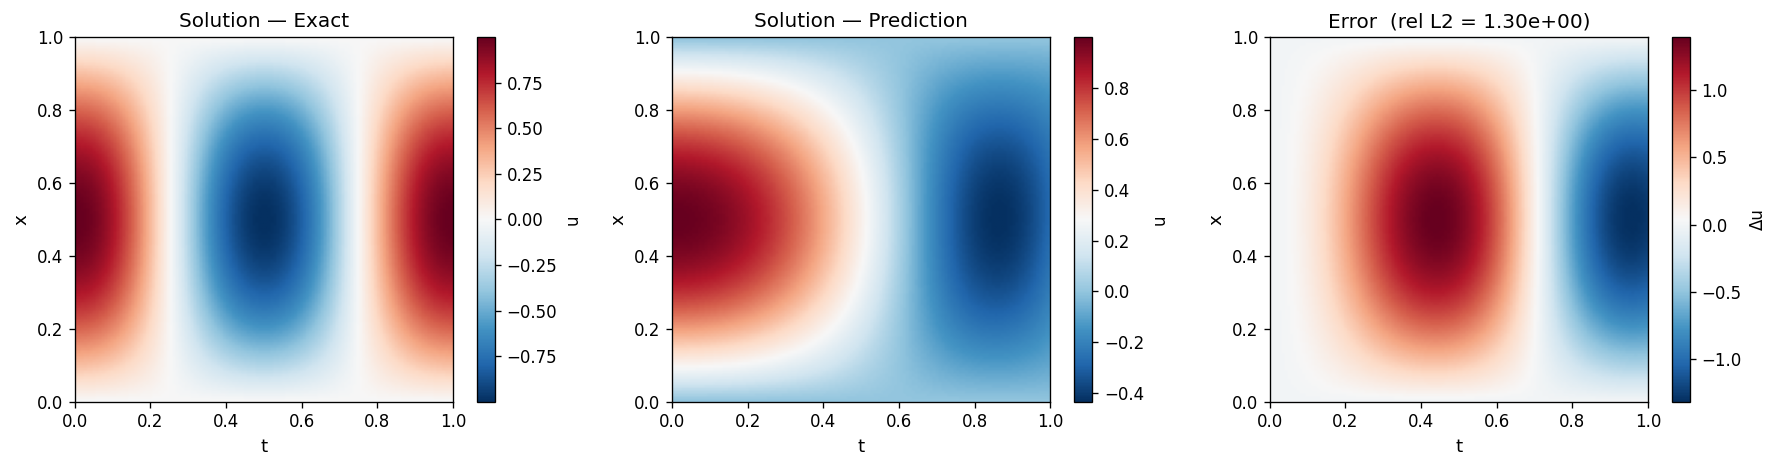

(<Figure size 1800x480 with 6 Axes>, 1.3049938678741455)

In [76]:
plot_solution_comparison(U_pred_q,U_true)
plot_solution_comparison(U_pred_c,U_true)
plot_solution_comparison(U_pred_q_w,U_true)


### 2.1 - Compare power spectra

QPINN power spectrum
Saved: ../figures/demo_fourier/power_spectrum_q.png


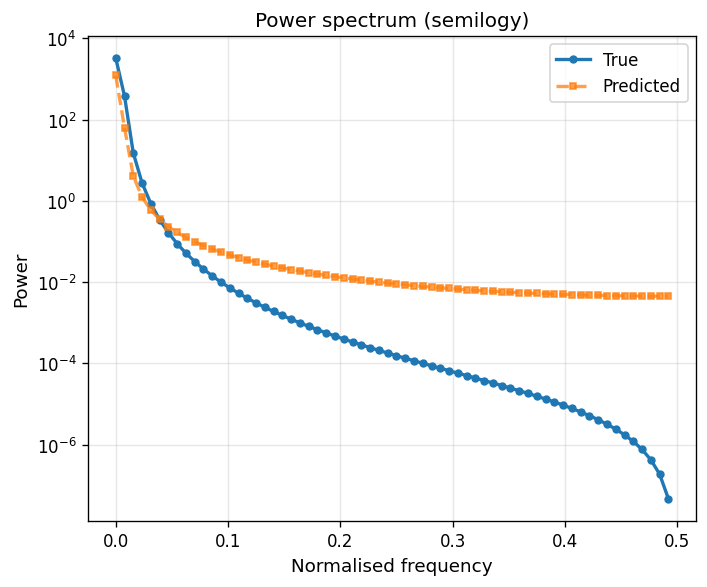

Classical power spectrum
Saved: ../figures/demo_fourier/power_spectrum_c.png


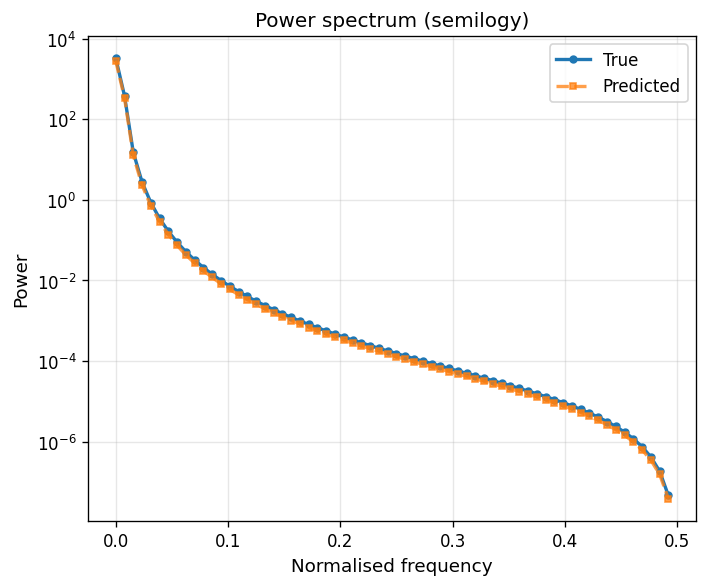

QPINN_weights power spectrum
Saved: ../figures/demo_fourier/power_spectrum_c.png


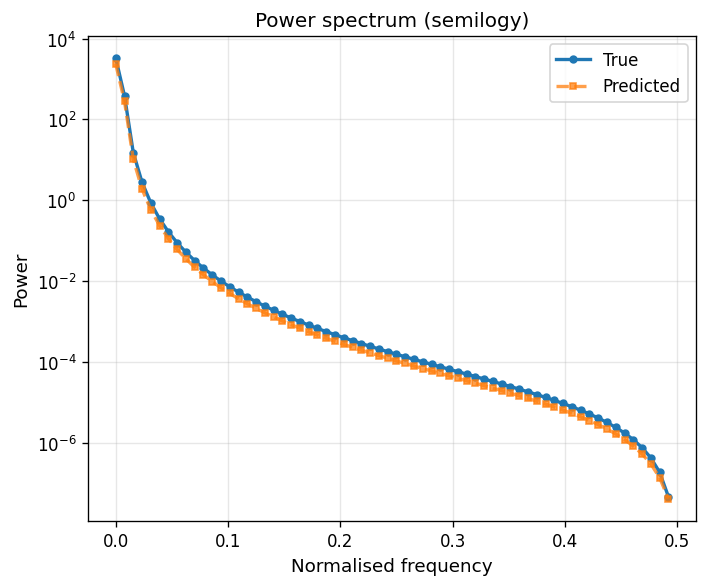

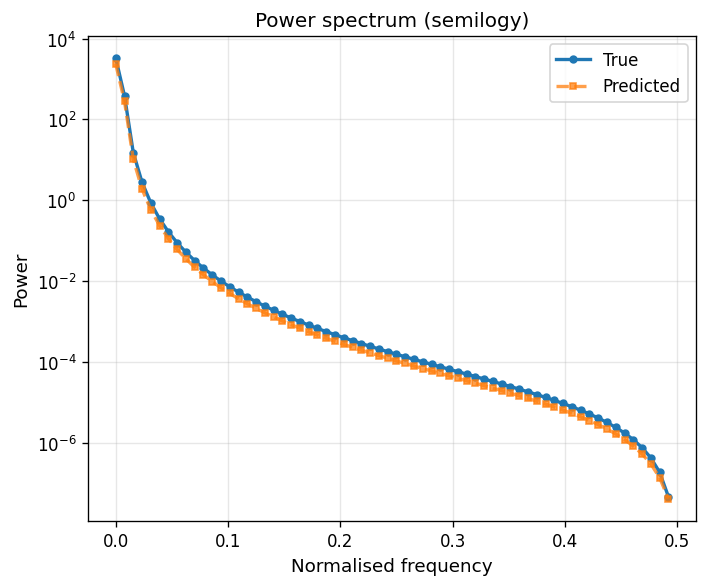

In [77]:
print("QPINN power spectrum")
plot_power_spectrum(U_pred_q, U_true, save_path="../figures/demo_fourier/power_spectrum_q.png", exclude_0_mode=False)

print("Classical power spectrum")
plot_power_spectrum(U_pred_c, U_true, save_path="../figures/demo_fourier/power_spectrum_c.png", exclude_0_mode=False)

print("QPINN_weights power spectrum")
plot_power_spectrum(U_pred_q_w, U_true, save_path="../figures/demo_fourier/power_spectrum_c.png", exclude_0_mode=False)

### 2.2 Compare per-mode L2 error

QPINN mode errors
Saved: ../figures/fourier_demo/l2_error_Q.png


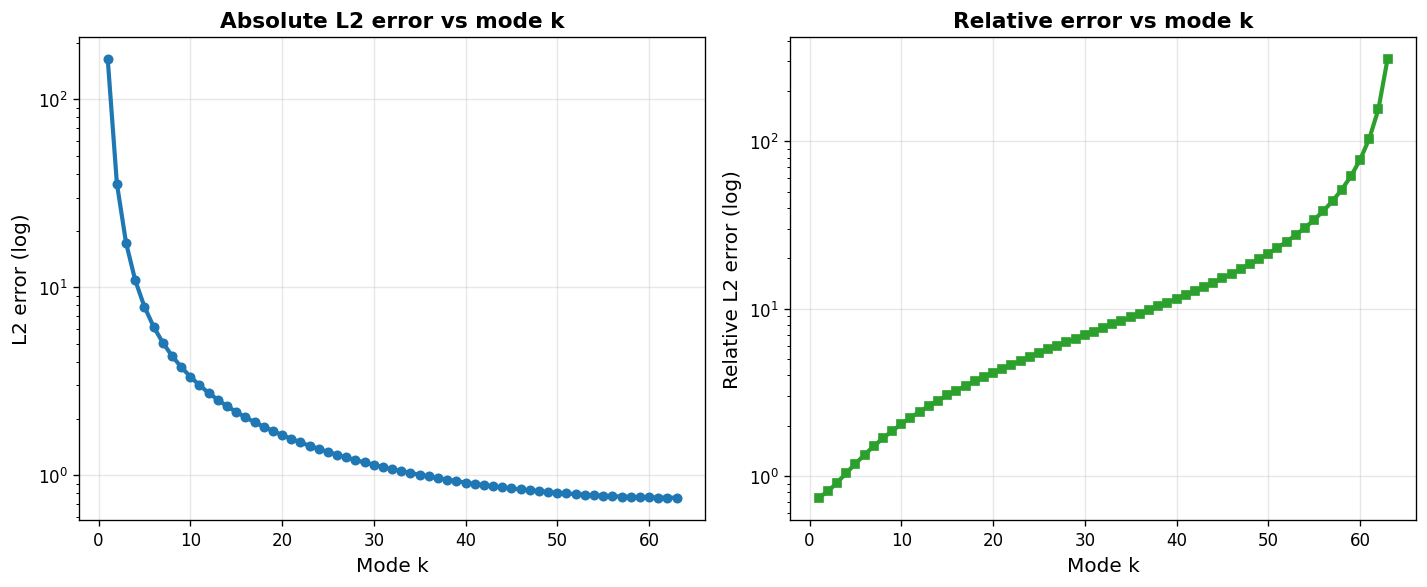

Classical mode errors
Saved: ../figures/fourier_demo/l2_error_C.png


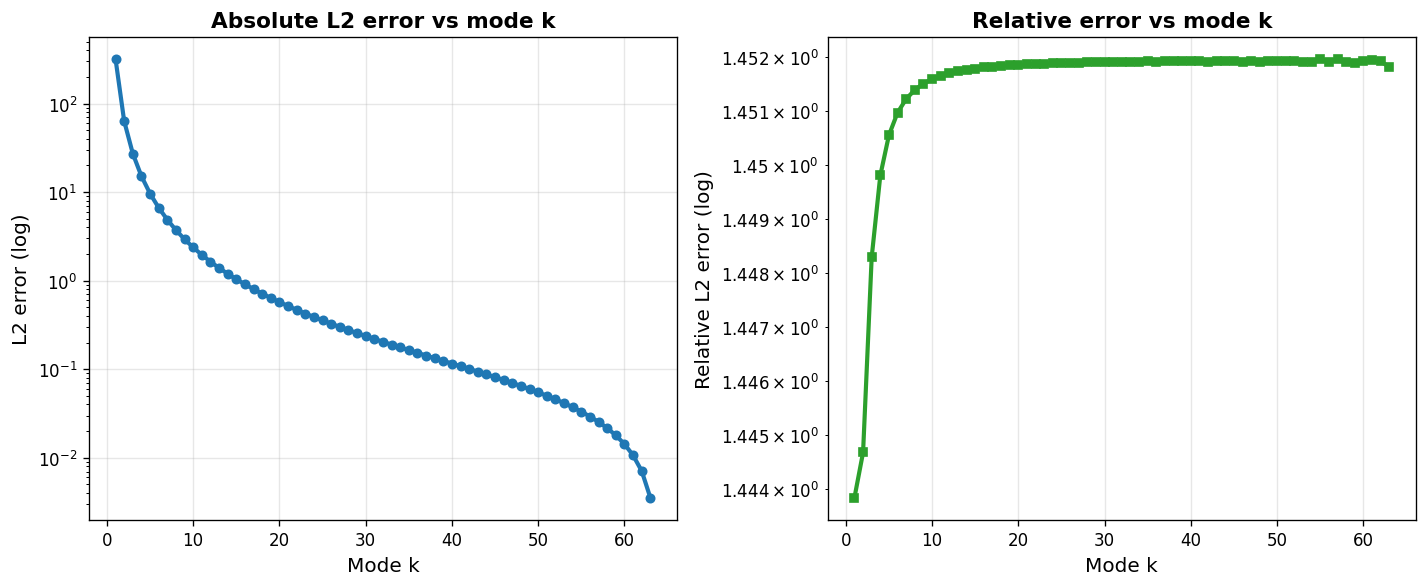

QPINN_weights mode errors
Saved: ../figures/fourier_demo/l2_error_Q_weights.png


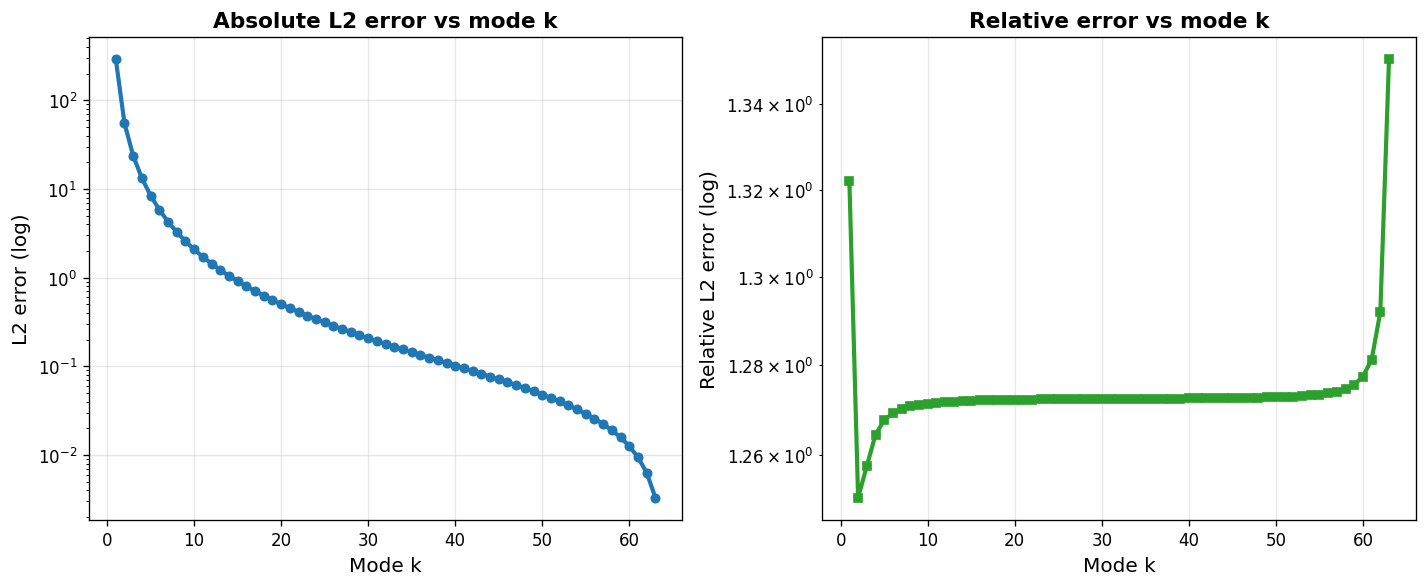

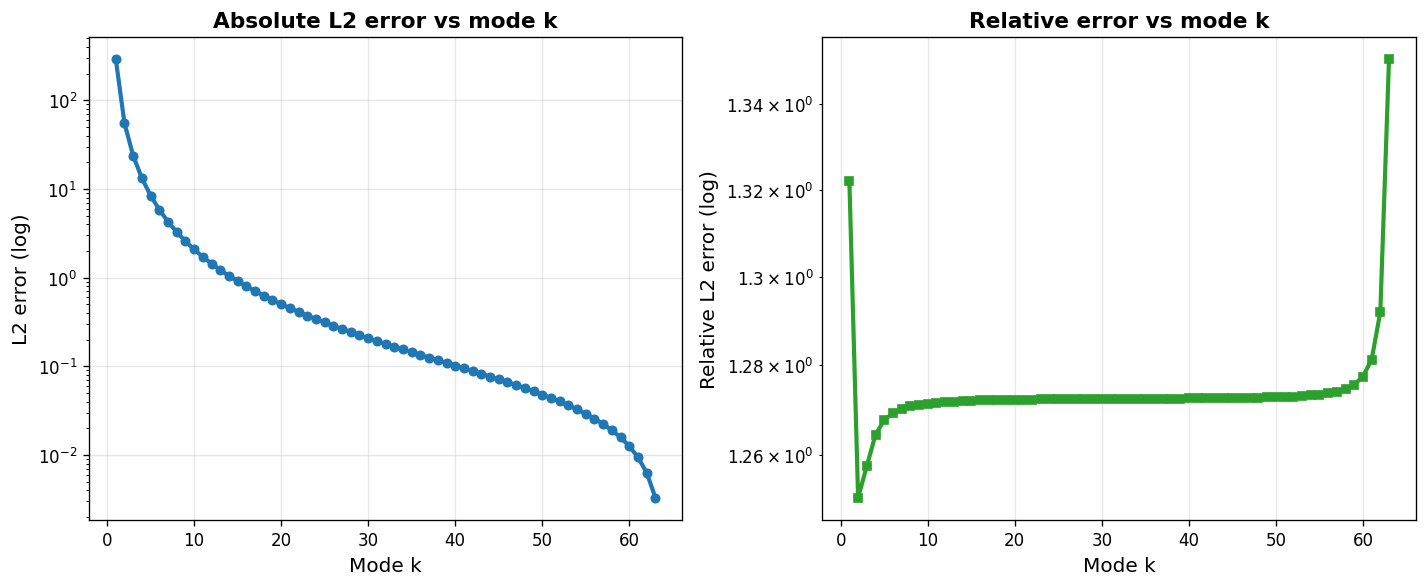

In [78]:
print("QPINN mode errors")
plot_mode_l2_errors(U_pred_q, U_true,
                    save_path="../figures/fourier_demo/l2_error_Q.png")

print("Classical mode errors")
plot_mode_l2_errors(U_pred_c, U_true,
                    save_path="../figures/fourier_demo/l2_error_C.png")

print("QPINN_weights mode errors")
plot_mode_l2_errors(U_pred_q_w, U_true,
                    save_path="../figures/fourier_demo/l2_error_Q_weights.png")



## Compare directly

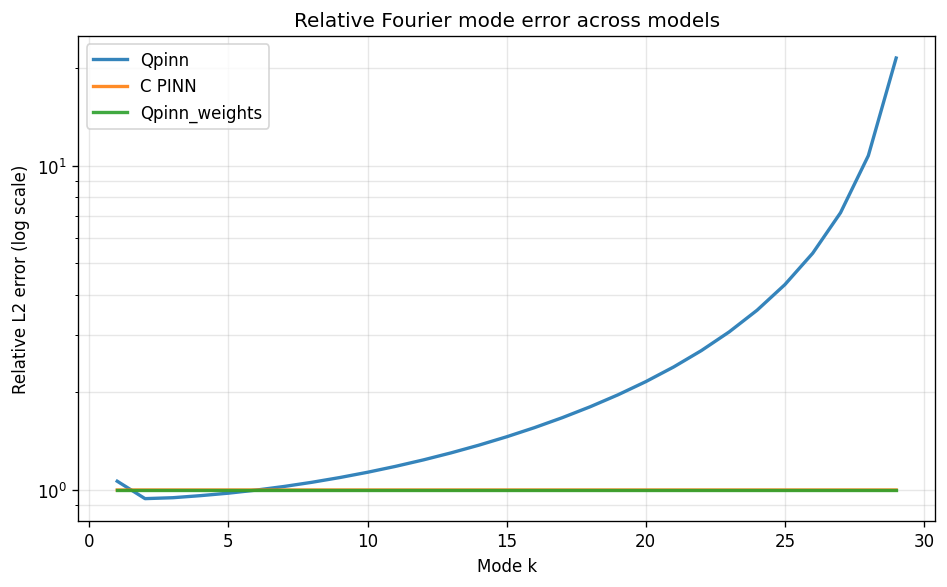

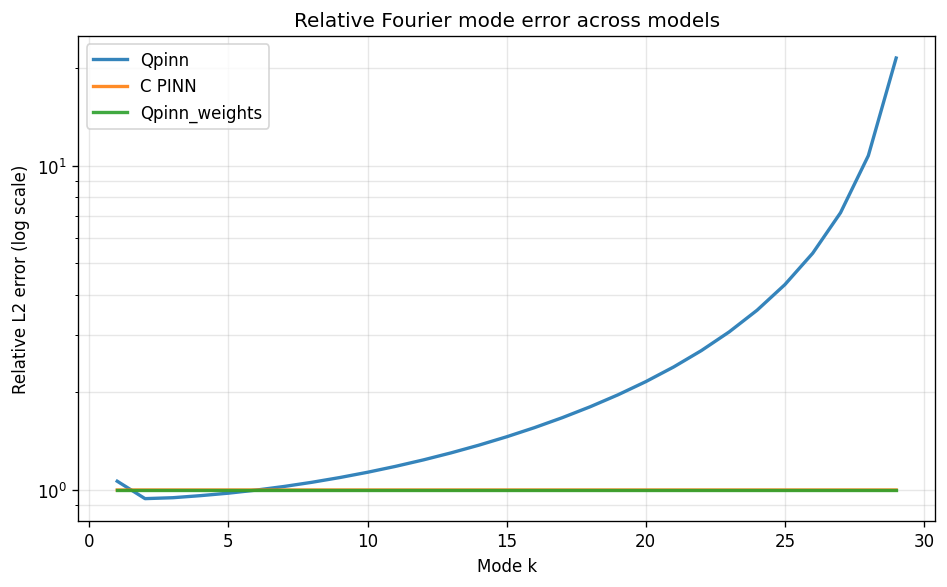

In [16]:


plot_multi_model_l2_error(U_true, [U_pred_q, U_pred_c,U_pred_q_w],["Qpinn", "C PINN","Qpinn_weights"])